In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import random
from scipy.stats import kurtosis
from generator import SyntheticMarketGenerator
import plotting_functions_v2 as pf
import backtester_functions_v2 as bf

c:\Users\scott\Desktop\Ovtlyr Work\Synthetic_stop_testing\sythetic_stock\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
gen = SyntheticMarketGenerator()

Kurtosis = 26.56701819003137
B&H% Ret: 259.10895486373454
Startegy % Ret: 101.15226862972241


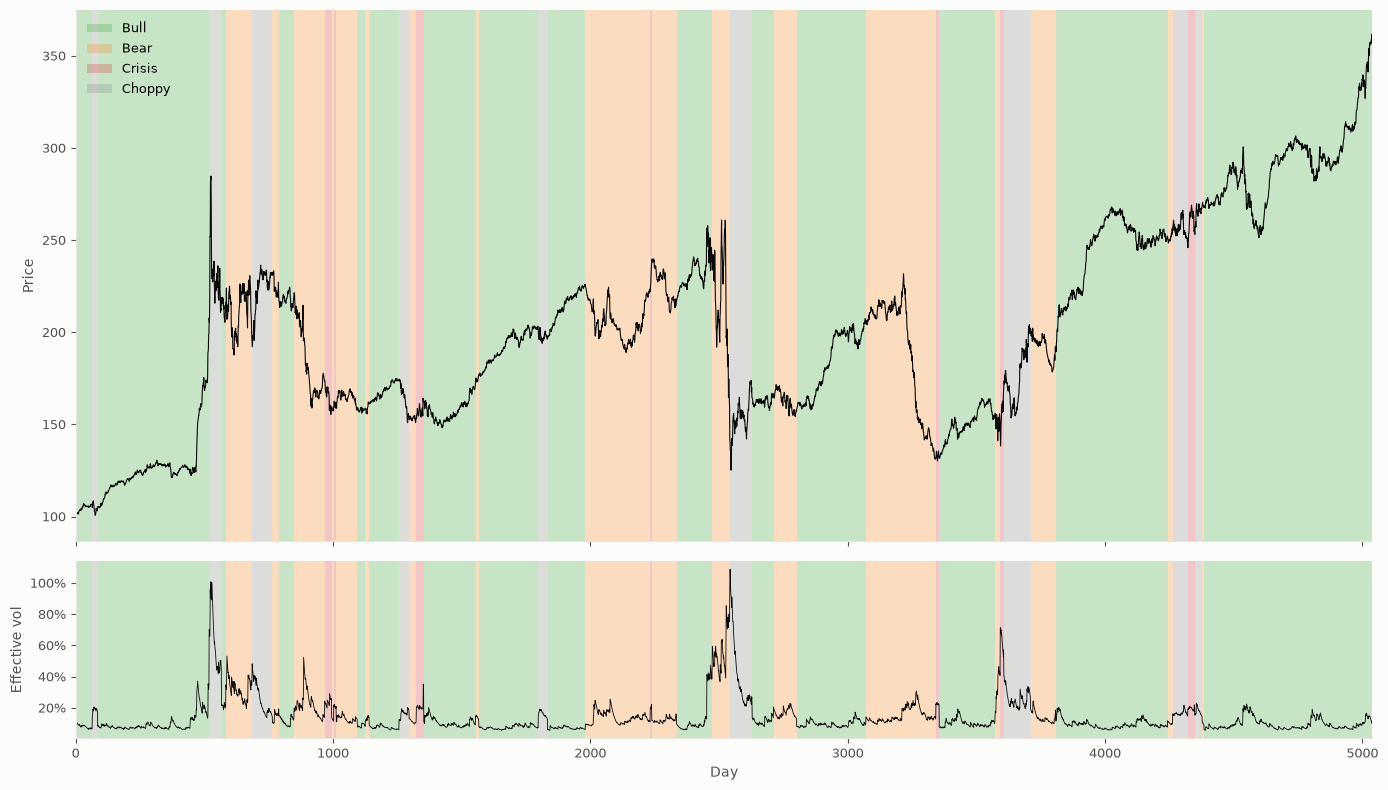

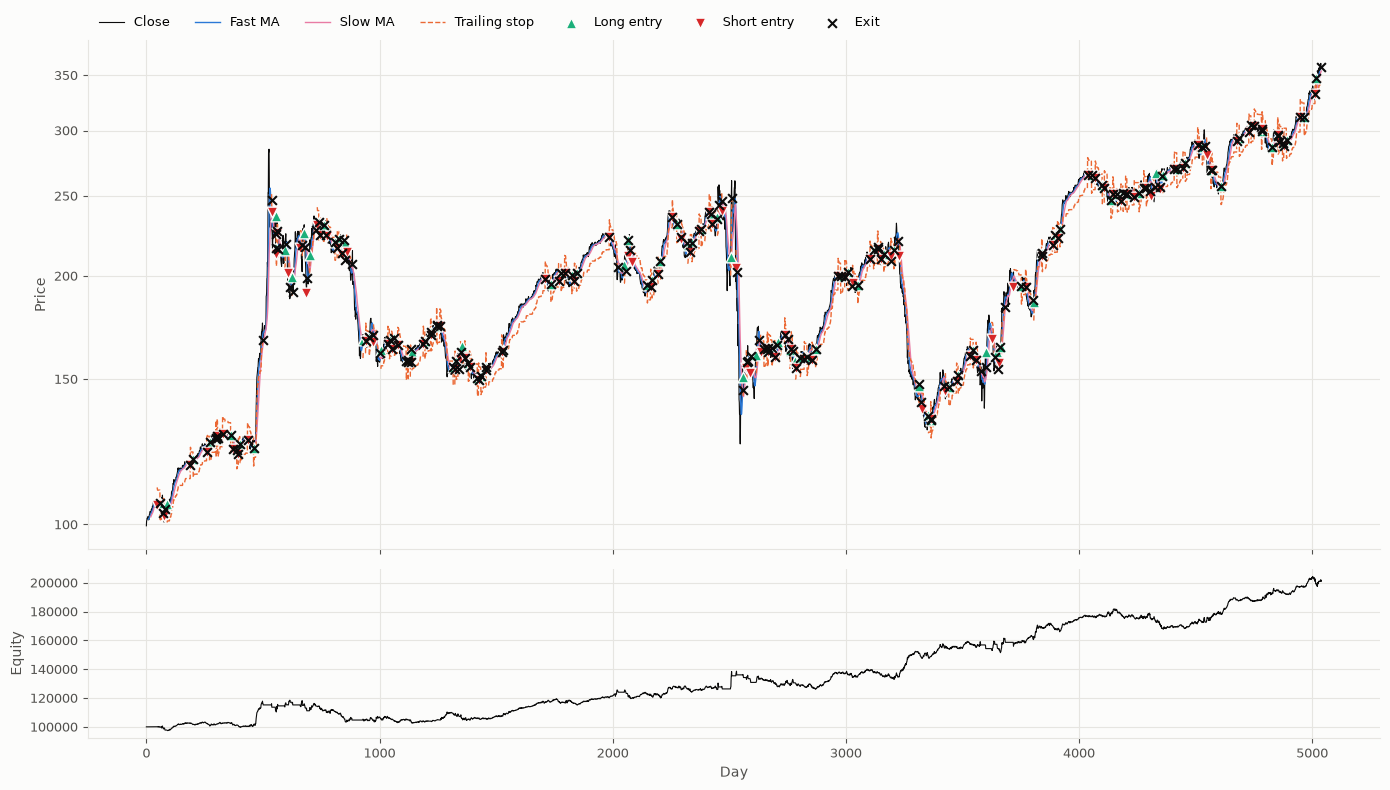

In [14]:
SEED = random.randint(0,1000000)
df  = gen.generate(T=252*20, S0=100.0, seed=SEED)
print(f"Kurtosis = {kurtosis(df['log_return'])}")



# res = bf.backtest_ma_atr(df, fast=10, slow=20, atr_period=14,stop_type = 'atr', trail_mult=3.0,cost_bps=0,sizing={'method': 'fixed_risk', 'risk_pct': 0.02})
res = bf.backtest_ma_atr(df, fast=10, slow=20, atr_period=14,stop_type = 'percent', trail_pct = 0.05,cost_bps=0,sizing={'method': 'fixed_risk', 'risk_pct': 0.02})

print (f"B&H% Ret: {100*(df['price'].values[-1] - df['price'].values[0])/df['price'].values[0]}")#
print(f"Startegy % Ret: {100*(res['daily'].equity.values[-1] - res['daily'].equity.values[0])/(res['daily'].equity.values[0])}")
pf.plot_with_regimes(df, gen.regime_params)
pf.plot_backtest(res)

Backtesting (11 workers): 100%|██████████| 29000/29000 [01:45<00:00, 275.18it/s]


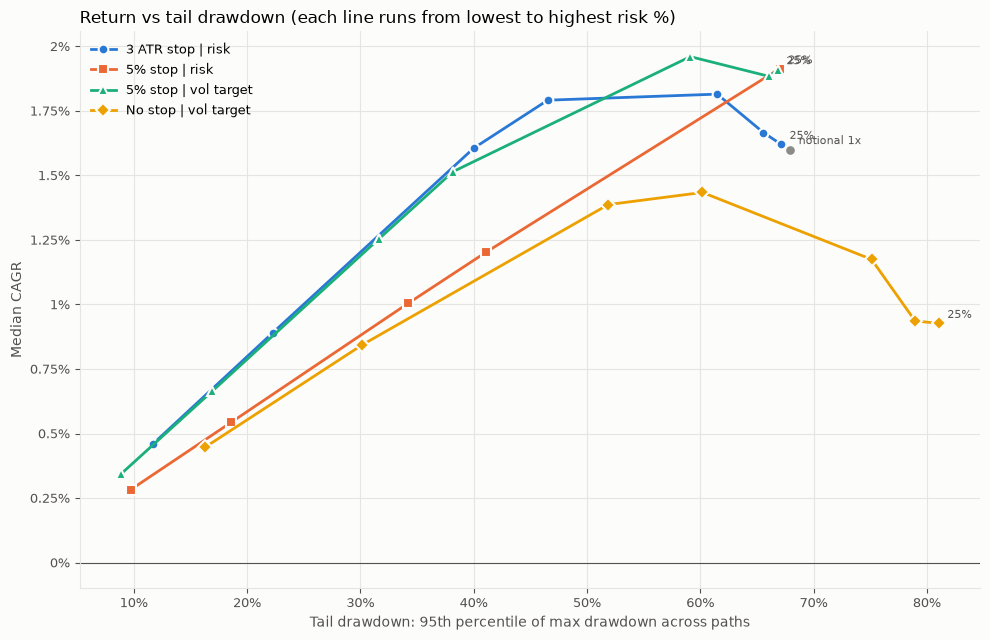

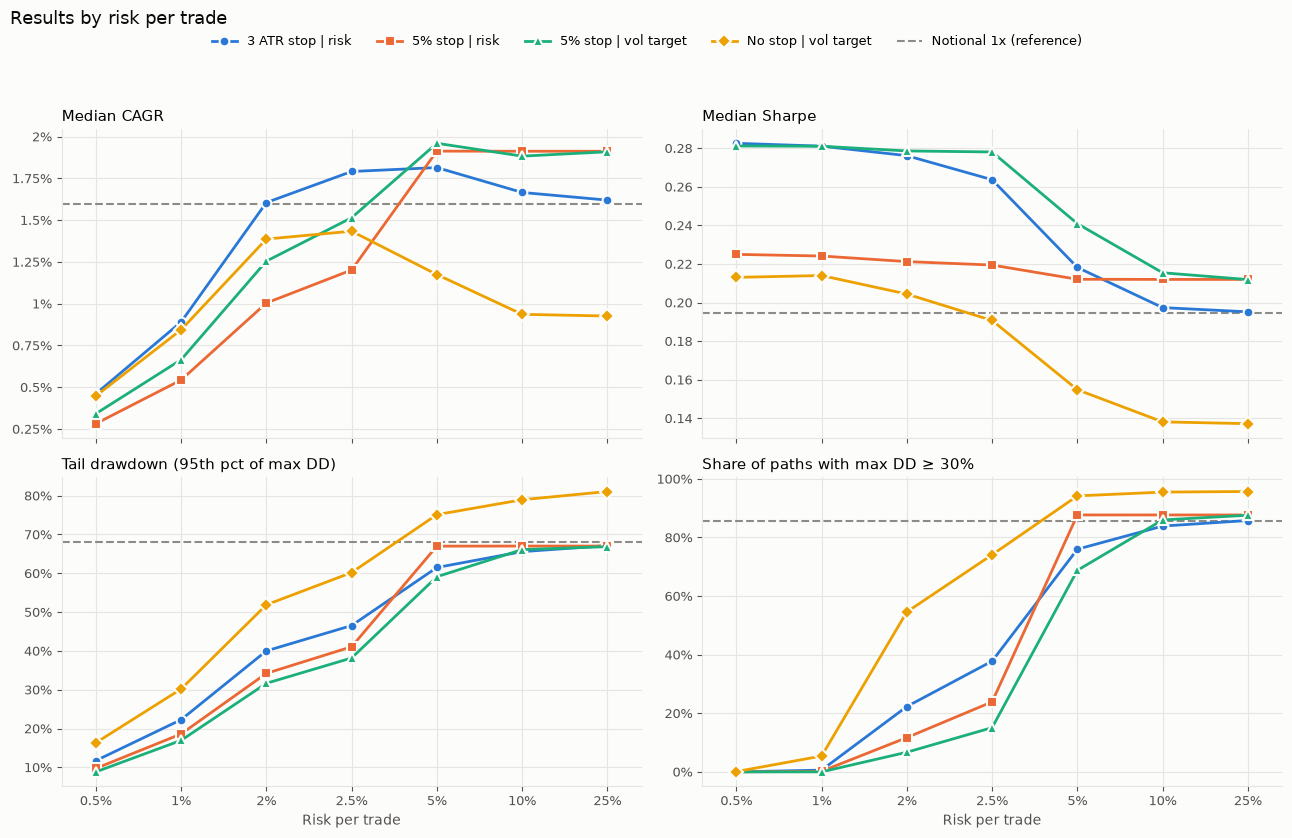

In [4]:
STOP_PCT   = 0.05   # percent stop distance
ATR_MULT   = 3      # ATR stop multiple
ATR_PERIOD = 14

# Typical ATR as a % of price, so the "5% stop | vol target" rows take the same
# average risk per trade as their label
sample = bf.generate_paths(gen, range(100), T=252*20, S0=100)
typical_atr_pct = np.median([(bf.add_atr(df.copy(), ATR_PERIOD)[f'atr_{ATR_PERIOD}'] / df['close']).median()for df in sample.values()])

risks = [0.005, 0.01, 0.02, 0.025, 0.05, 0.10, 0.25]
configs = {'notional 1x': {'sizing': {'method': 'notional', 'fraction': 1.0}}}

for r in risks:
    label = f'{r:.1%}'
    # ATR stop, sized by stop distance (= volatility-adjusted)
    configs[f'{ATR_MULT:g} ATR stop | risk {label}'] = {'stop_type': 'atr', 'trail_mult': ATR_MULT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'fixed_risk', 'risk_pct': r}}
    # Percent stop, sized by stop distance (= constant notional of r / STOP_PCT)
    configs[f'{STOP_PCT:.0%} stop | risk {label}'] = {'stop_type': 'percent', 'trail_pct': STOP_PCT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'fixed_risk', 'risk_pct': r}}
    # Percent stop, sized by ATR (volatility-adjusted size, fixed stop)
    configs[f'{STOP_PCT:.0%} stop | vol target {label}'] = {'stop_type': 'percent', 'trail_pct': STOP_PCT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'vol_target', 'atr_pct': r * typical_atr_pct / STOP_PCT}}
    # No stop, sized exactly like the ATR-stop rows, exit on opposite cross only
    configs[f'No stop | vol target {label}'] = {'stop_type': 'none', 'trail_mult': ATR_MULT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'vol_target', 'atr_pct': r / ATR_MULT}}

table, per_path = bf.compare_parallel(gen, range(1000), configs, T=252*20, S0=100,cost_bps=5, return_per_path=True)

pf.plot_frontier(table)
pf.plot_by_risk(table)

# bf.ruin_table(per_path, thresholds=[0.1, 0.2, 0.3, 0.4, 0.5])                  # fall from peak
# bf.ruin_table(per_path, thresholds=[0.1, 0.2, 0.3, 0.4, 0.5], measure='loss')  # fall below starting equity

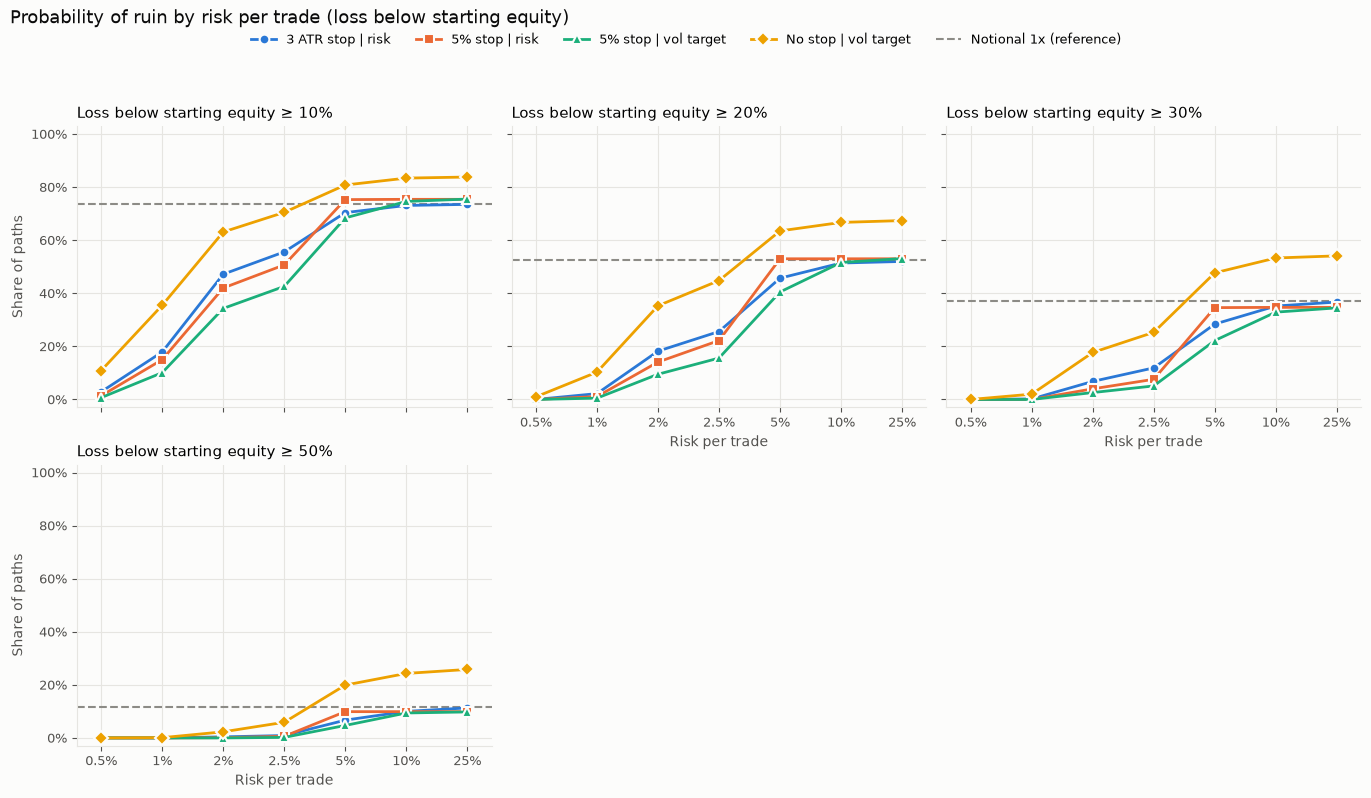

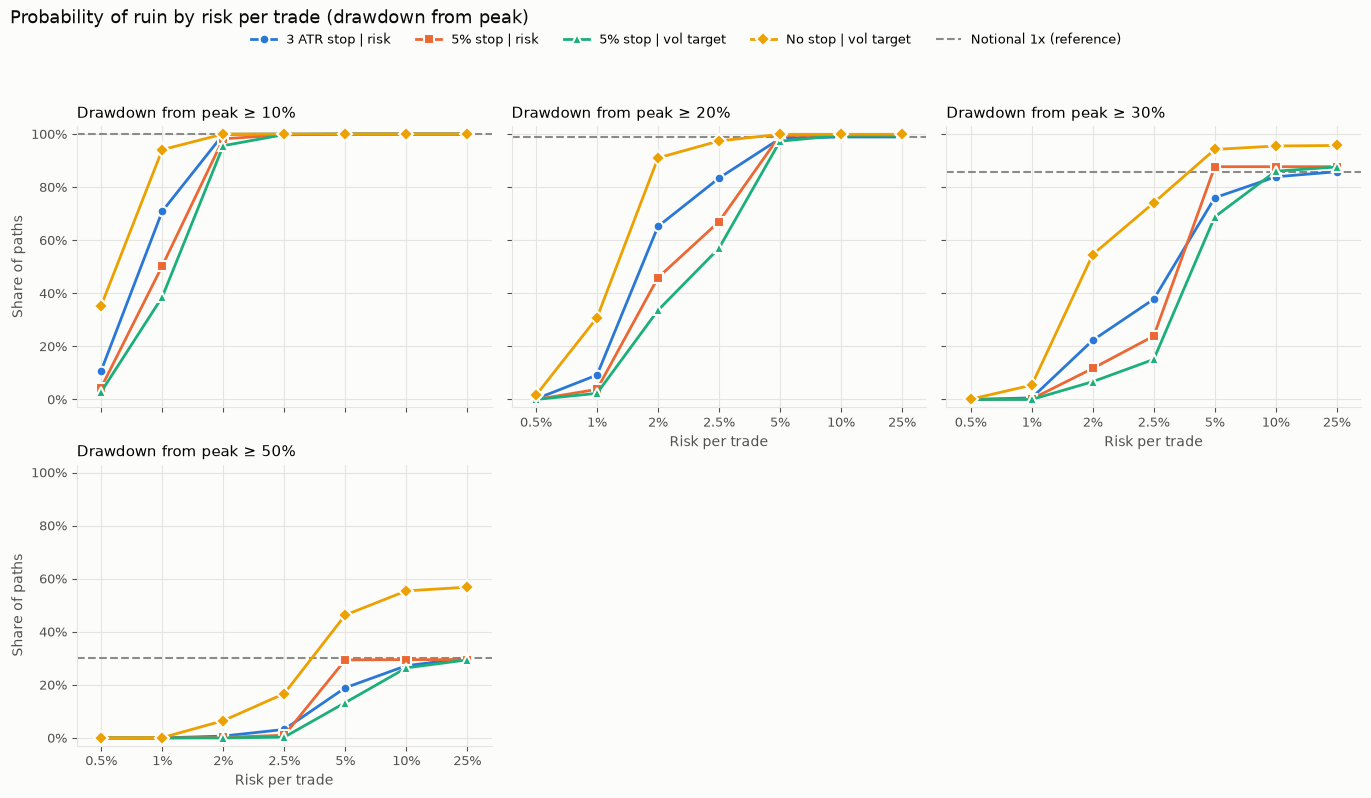

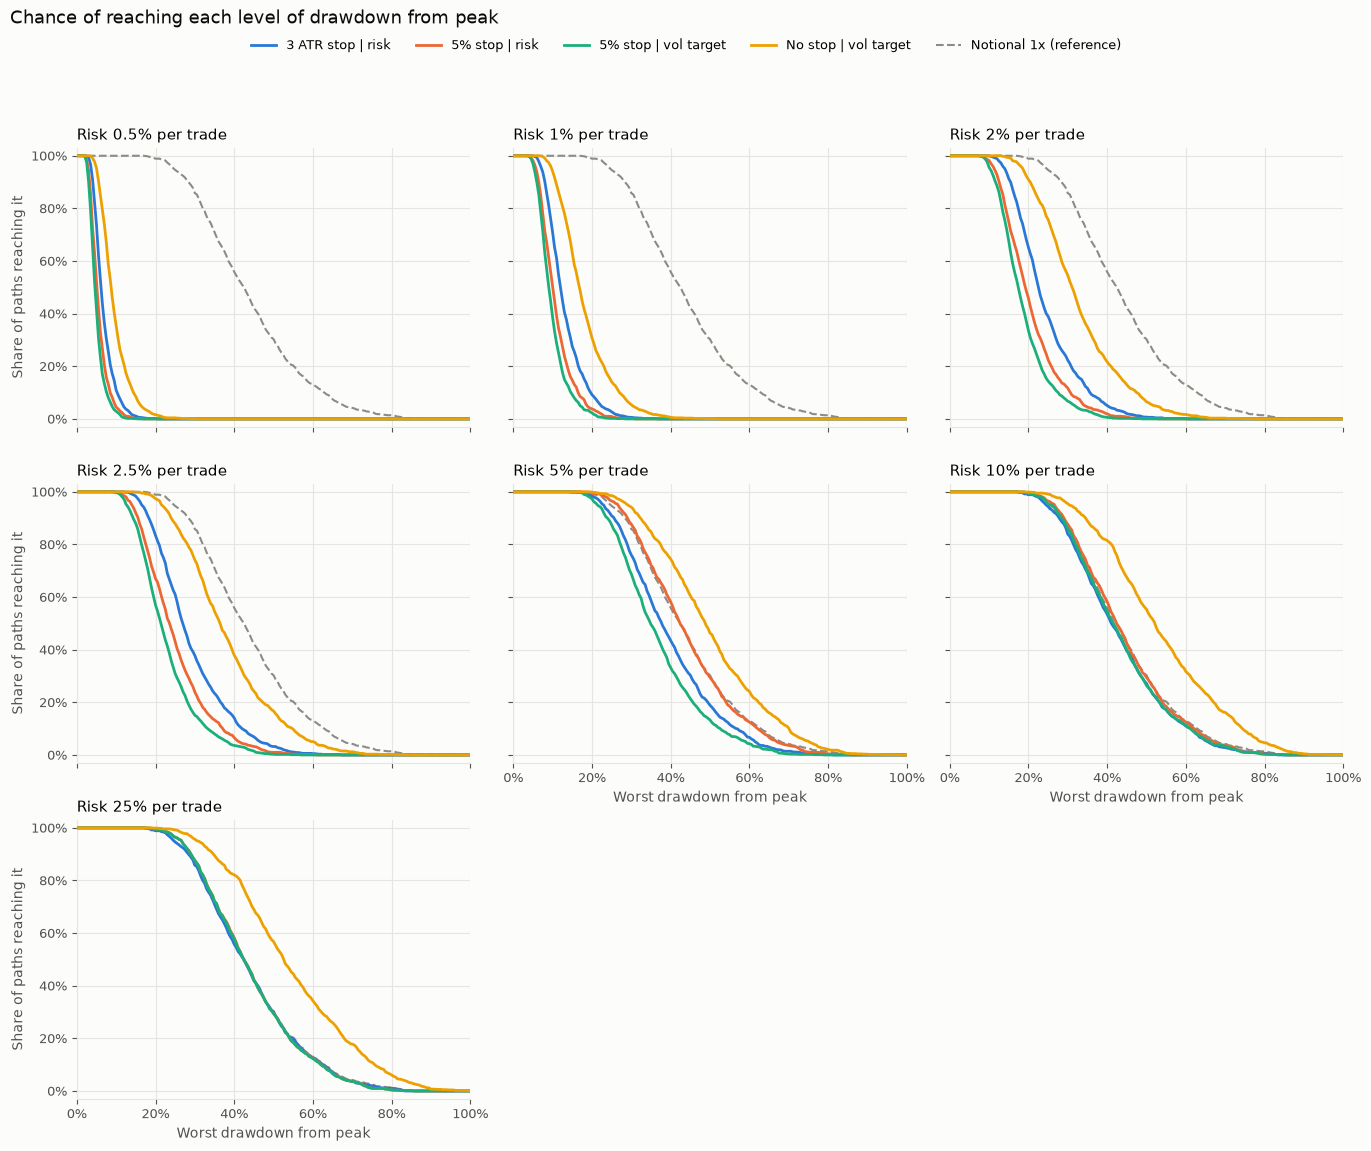

In [6]:
pf.plot_ruin_by_risk(per_path, thresholds=(0.1, 0.2, 0.3, 0.5),measure='loss')   # measure='loss' for loss below starting equity
pf.plot_ruin_by_risk(per_path, thresholds=(0.1, 0.2, 0.3, 0.5),measure='drawdown')   # measure='loss' for loss below starting equity
pf.plot_ruin_curves(per_path) 